In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
dataset_root = kagglehub.dataset_download(
    "belsonraja/face-mask-dataset-with-and-without-mask"
)

base_path = os.path.join(
    dataset_root,
    "facemask-dataset",
    "dataset"
)

categories = ["without_mask", "with_mask"]

print("Dataset path:", base_path)
print("Categories:", os.listdir(base_path))

Dataset path: /Users/kulvindersinghthakur/.cache/kagglehub/datasets/belsonraja/face-mask-dataset-with-and-without-mask/versions/3/facemask-dataset/dataset
Categories: ['with_mask', 'without_mask']


In [4]:
# Load and preprocess images
data = []
labels = []

IMG_SIZE = 64

for category in categories:

    folder_path = os.path.join(base_path, category)
    label = categories.index(category)

    for file in os.listdir(folder_path):

        img_path = os.path.join(folder_path, file)

        img = cv2.imread(img_path)

        if img is None:
            continue

        # Convert to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Resize to 64 x 64
        gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE))

        # Flatten 2D image into 1D vector
        flattened = gray.flatten()

        data.append(flattened)
        labels.append(label)

X = np.array(data, dtype=np.float32)
y = np.array(labels)

# Normalize pixel values
X = X / 255.0

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", np.unique(y, return_counts=True))

libpng warning: iCCP: known incorrect sRGB profile


X shape: (3833, 4096)
y shape: (3833,)
Classes: (array([0, 1]), array([1918, 1915]))


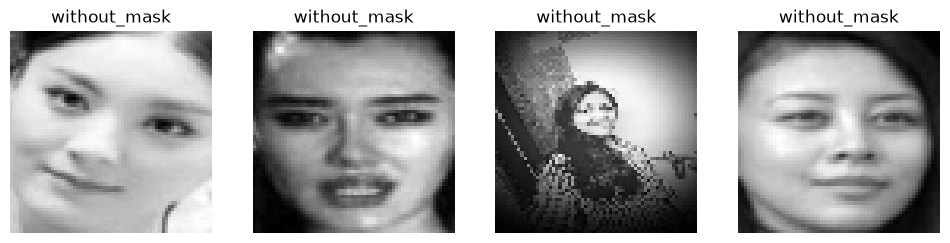

In [5]:
# 4.3 — Visualize your images

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i in range(4):
    axes[i].imshow(
        X[i].reshape(64, 64),
        cmap="gray"
    )
    axes[i].set_title(categories[y[i]])
    axes[i].axis("off")

plt.show()

In [6]:
# Step 4.4 — Split training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (3066, 4096)
Testing images: (767, 4096)


In [9]:
# 5.1 StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)

(3066, 4096)


In [10]:
# 5.2 Dimensionality reduction

pca = PCA(n_components=100, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Before PCA:", X_train.shape)
print("After PCA:", X_train_pca.shape)

print("Variance retained:",
      pca.explained_variance_ratio_.sum())

Before PCA: (3066, 4096)
After PCA: (3066, 100)
Variance retained: 0.8940216


In [11]:
# 5.3 Train Linear SVM

svm_model = SVC(kernel="linear", C=1.0)

svm_model.fit(X_train_pca, y_train)

print("SVM training completed!")

SVM training completed!


In [12]:
#5.3 Test accuracy

y_pred = svm_model.predict(X_test_pca)

accuracy = accuracy_score(y_test, y_pred)

print("SVM Test Accuracy:", accuracy * 100, "%")

print(classification_report(
    y_test,
    y_pred,
    target_names=categories
))

SVM Test Accuracy: 73.14211212516297 %
              precision    recall  f1-score   support

without_mask       0.74      0.72      0.73       384
   with_mask       0.73      0.74      0.73       383

    accuracy                           0.73       767
   macro avg       0.73      0.73      0.73       767
weighted avg       0.73      0.73      0.73       767



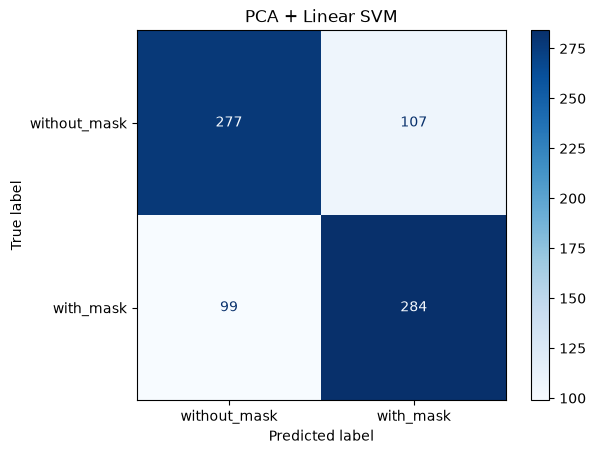

In [13]:
# 5.5 Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=categories,
    cmap="Blues"
)

plt.title("PCA + Linear SVM")
plt.show()

In [14]:
# 6.1 SVM model saved successfully

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    {
        "scaler": scaler,
        "pca": pca,
        "svm": svm_model,
        "img_size": 64,
        "categories": categories
    },
    "models/pca_svm_mask.joblib"
)

print("SVM model saved successfully!")

SVM model saved successfully!


In [15]:
# 6.2 Load and verify the saved model

saved = joblib.load("models/pca_svm_mask.joblib")

loaded_scaler = saved["scaler"]
loaded_pca = saved["pca"]
loaded_svm = saved["svm"]

X_check = loaded_scaler.transform(X_test[:5])
X_check = loaded_pca.transform(X_check)

predictions = loaded_svm.predict(X_check)

print("Predictions:", predictions)
print("Actual:", y_test[:5])

Predictions: [1 1 1 0 0]
Actual: [1 1 1 0 0]


In [16]:
# 7.1 Load Haar Cascade

import cv2
import numpy as np

haar = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

print("Haar Cascade loaded:", not haar.empty())

Haar Cascade loaded: True


In [17]:
# 7.2 Create SVM prediction function

def detect_face_mask_svm(face):

    # Match training preprocessing
    gray = cv2.cvtColor(face, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (64, 64))

    # Flatten and normalize
    img = gray.flatten().astype(np.float32) / 255.0
    img = img.reshape(1, -1)

    # StandardScaler -> PCA -> SVM
    img_scaled = loaded_scaler.transform(img)
    img_pca = loaded_pca.transform(img_scaled)

    prediction = int(loaded_svm.predict(img_pca)[0])

    return prediction

In [22]:
cap = cv2.VideoCapture(0)

try:
    while True:
        ret, frame = cap.read()

        if not ret:
            break

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        faces = haar.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(100, 100)
        )

        # Detect only the largest face
        if len(faces) > 0:
            x, y, w, h = max(
                faces,
                key=lambda f: f[2] * f[3]
            )

            face = frame[y:y+h, x:x+w]
            prediction = detect_face_mask_svm(face)

            label = "MASK" if prediction == 1 else "WITHOUT MASK"
            color = (0, 255, 0) if prediction == 1 else (0, 0, 255)

            cv2.rectangle(
                frame, (x, y), (x+w, y+h), color, 2
            )

            cv2.putText(
                frame, label,
                (x, max(y-10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, color, 2
            )
        else:
            cv2.putText(
                frame, "NO FACE DETECTED",
                (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7, (0, 0, 255), 2
            )

        cv2.imshow("PCA + SVM Mask Detection", frame)

        # Press x or ESC to stop
        key = cv2.waitKey(1) & 0xFF
        if key == ord("x") or key == 27:
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

KeyboardInterrupt: 

In [ ]:
cap.release()
cv2.destroyAllWindows()